Data Preprocessing

In [54]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder,MinMaxScaler,StandardScaler
import seaborn as sb
import numpy as np

upload read excel file

In [55]:
df=pd.read_excel(r"C:\Users\91636\OneDrive\Desktop\Data-Analytics-Portfolio\Python\ML_practice\ML_data.xlsx")

inspect

In [56]:
df.sample(5)

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
4,105,IT,55,39.0,4,3,Female,Fail
2,103,CSE,91,88.0,15,0,Female,Pass
1,102,IT,62,45.0,5,2,Male,Fail
0,101,CSE,85,78.0,12,0,Female,Pass
3,104,ECE,74,NaN,8,1,Male,Pass


In [57]:
df.head(5)

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,101,CSE,85,78.0,12,0,Female,Pass
1,102,IT,62,45.0,5,2,Male,Fail
2,103,CSE,91,88.0,15,0,Female,Pass
3,104,ECE,74,NaN,8,1,Male,Pass
4,105,IT,55,39.0,4,3,Female,Fail


In [58]:
df

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,101,CSE,85,78.0,12,0,Female,Pass
1,102,IT,62,45.0,5,2,Male,Fail
2,103,CSE,91,88.0,15,0,Female,Pass
3,104,ECE,74,NaN,8,1,Male,Pass
4,105,IT,55,39.0,4,3,Female,Fail


define feature

In [59]:
x=df.drop("Final_Result",axis=1)
x

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender
0,101,CSE,85,78.0,12,0,Female
1,102,IT,62,45.0,5,2,Male
2,103,CSE,91,88.0,15,0,Female
3,104,ECE,74,NaN,8,1,Male
4,105,IT,55,39.0,4,3,Female


define target

In [60]:
y=df["Final_Result"]
print(y)


0    Pass
1    Fail
2    Pass
3    Pass
4    Fail
Name: Final_Result, dtype: str


find missing values

In [61]:
df.isnull()

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,True,False,False,False,False
4,False,False,False,False,False,False,False,False


In [62]:
df.isnull().sum()

Student_ID        0
Department        0
Attendance        0
Internal_Marks    1
Study_Hours       0
Backlogs          0
Gender            0
Final_Result      0
dtype: int64

impute-missing values replace using mean

In [63]:
df["Internal_Marks"]=df["Internal_Marks"].fillna(df['Internal_Marks'].mean())

In [64]:
df["Internal_Marks"]

0    78.0
1    45.0
2    88.0
3    62.5
4    39.0
Name: Internal_Marks, dtype: float64

when we have binary values to encode using LabelEncoder

create labelencoder object

In [65]:
encode=LabelEncoder()

train the model

In [66]:
df["Gender_encoded"]=encode.fit_transform(df["Gender"])

In [67]:
df["Gender"]

0    Female
1      Male
2    Female
3      Male
4    Female
Name: Gender, dtype: str

In [68]:
df[["Gender","Gender_encoded"]]

,Gender,Gender_encoded
0,Female,0
1,Male,1
2,Female,0
3,Male,1
4,Female,0


In [69]:
df

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result,Gender_encoded
0,101,CSE,85,78.0,12,0,Female,Pass,0
1,102,IT,62,45.0,5,2,Male,Fail,1
2,103,CSE,91,88.0,15,0,Female,Pass,0
3,104,ECE,74,62.5,8,1,Male,Pass,1
4,105,IT,55,39.0,4,3,Female,Fail,0


when we have nominal category values to encode using One_Hot encoding

In [70]:
pd.get_dummies(df,columns=["Department"])

,Student_ID,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result,Gender_encoded,Department_CSE,Department_ECE,Department_IT
0,101,85,78.0,12,0,Female,Pass,0,True,False,False
1,102,62,45.0,5,2,Male,Fail,1,False,False,True
2,103,91,88.0,15,0,Female,Pass,0,True,False,False
3,104,74,62.5,8,1,Male,Pass,1,False,True,False
4,105,55,39.0,4,3,Female,Fail,0,False,False,True


Normalization

when we have large scale range data to minimize using MinMaxScaler

create MinMax Scaler object

In [71]:
Scaler=MinMaxScaler()

Train the model

In [72]:
df["Study_hours_scaled"]=Scaler.fit_transform(df[["Study_Hours"]])
df["Study_hours_scaled"]

0    0.727273
1    0.090909
2    1.000000
3    0.363636
4    0.000000
Name: Study_hours_scaled, dtype: float64

In [73]:
df[["Study_Hours","Study_hours_scaled"]]

,Study_Hours,Study_hours_scaled
0,12,0.727273
1,5,0.090909
2,15,1.000000
3,8,0.363636
4,4,0.000000


Standardization

when we have large scale range to minimize using mean and stddev using StandardScaler

create StandardScaler object

In [74]:
std_scaler=StandardScaler()

train the model

In [75]:
df["Study_hours_std_scaled"]=std_scaler.fit_transform(df[["Study_Hours"]])
df["Study_hours_std_scaled"]

0    0.768025
1   -0.912029
2    1.488048
3   -0.192006
4   -1.152037
Name: Study_hours_std_scaled, dtype: float64

In [76]:
std_hrs=[4,5,6,7,8,50]
std_hrs

[4, 5, 6, 7, 8, 50]

<Axes: >

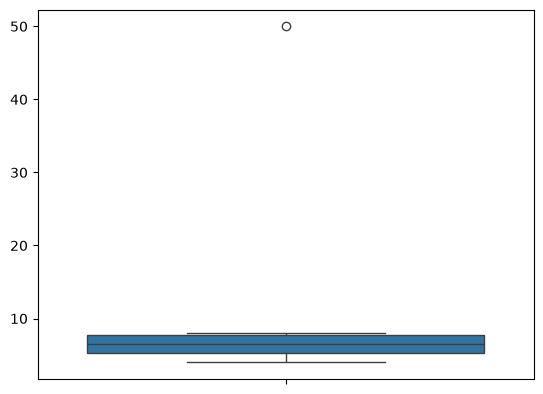

In [77]:
sb.boxplot(std_hrs)

In [78]:
income=[20000,22000,25000,30000,400000,500000]
income

[20000, 22000, 25000, 30000, 400000, 500000]

<Axes: >

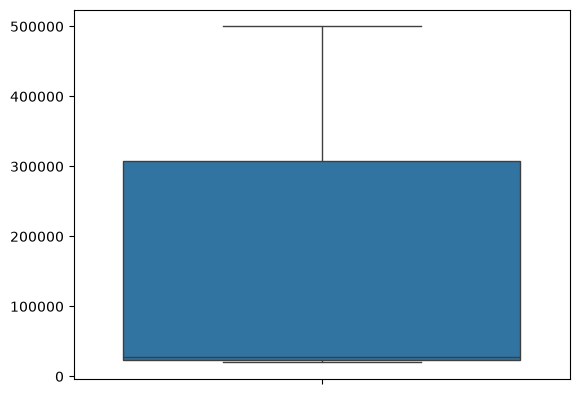

In [79]:
sb.boxplot(income)

<Axes: ylabel='Count'>

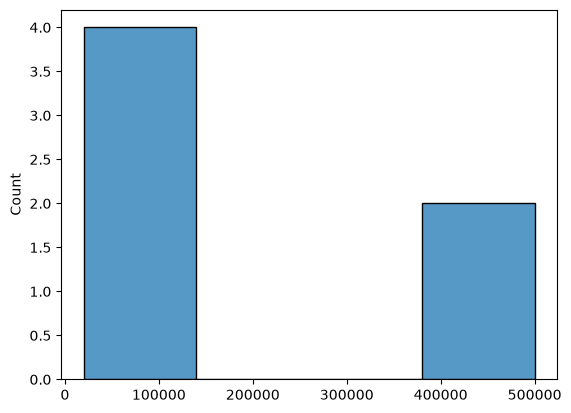

In [81]:
sb.histplot(income)

In [82]:
np.log1p([20000,22000,25000,30000,400000,500000])

array([ 9.90353755,  9.99884319, 10.1266711 , 10.30898599, 12.89922233,
       13.12236538])

In [83]:
pd.DataFrame([20000,22000,25000,30000,400000,500000]).skew()

0    1.054487
dtype: float64

In [85]:
pd.DataFrame(np.log1p([20000,22000,25000,30000,400000,500000])).skew()

0    0.943307
dtype: float64